# O que explica o preço dos imóveis à venda em São Paulo?

Este projeto começou na [Imersão Dados da Alura](../Imersão%20ALURA/), onde os anúncios de imóveis de São Paulo foram limpos, geolocalizados e cruzados com o Censo do IBGE, terminando numa regressão linear do preço em função da metragem (R² de 0,13). Aqui eu retomo essa base para responder à pergunta com mais cuidado: revisão da qualidade dos dados, mapa de preços por distrito, comparação de modelos com validação cruzada e análise do que mais pesa no preço.

## Resumo

- **A qualidade dos dados pesava mais do que a escolha do modelo.** A base tinha 1.235 grupos de anúncios duplicados, quase sempre com a metragem alterada em 5 m², e um sítio de 37.000 m². Só o sítio derrubava o R² do modelo do curso de 0,42 para 0,13.
- **A localização muda tudo.** A mediana do preço por m² vai de R$ 2.857 em São Mateus a R$ 15.000 no Jardim Paulista, 5,2 vezes mais.
- **Em metade dos imóveis, o melhor modelo erra menos de 20,4% do preço.** É um modelo de árvores de decisão (gradient boosting) com a localização. A regressão do curso, avaliada da mesma forma, erra menos de 37,6% em metade dos imóveis. Em validação cruzada, o R² sobe de 0,50 para 0,73.
- **Metragem, localização e renda do entorno explicam a maior parte do preço.** Quartos, banheiros e vagas acrescentam pouco quando essas três já estão no modelo.

## 1. Configuração

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import make_scorer, r2_score
from sklearn.model_selection import KFold, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer

# Caminhos relativos à pasta do notebook: os dados vêm das aulas do curso, sem cópias
PASTA_PROJETO = Path.cwd()
RAIZ = PASTA_PROJETO.parent
ARQUIVO_ANUNCIOS = RAIZ / "Imersão ALURA" / "05" / "dados_vendas_censo.csv"
ARQUIVO_SETORES = RAIZ / "Imersão ALURA" / "04" / "sp_setores_consitarios" / "35SEE250GC_SIR.shp"
PASTA_IMG = PASTA_PROJETO / "img"
PASTA_IMG.mkdir(exist_ok=True)
assert ARQUIVO_ANUNCIOS.exists(), f"Execute o notebook a partir da pasta imoveis-sp/ (não achei {ARQUIVO_ANUNCIOS})"

SEMENTE = 54     # a mesma semente da aula 05
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", "_").replace(".", ",").replace("_", "."))

In [2]:
# Formatação de números no padrão brasileiro
def inteiro(valor):
    """1234567.8 -> '1.234.568'"""
    return f"{valor:,.0f}".replace(",", ".")

def decimal(valor, casas=2):
    """0.1298 -> '0,13'"""
    if round(valor, casas) == 0:
        valor = 0.0          # evita '-0,00'
    return f"{valor:.{casas}f}".replace(".", ",")

def reais(valor):
    """1234567.8 -> 'R$ 1.234.568'"""
    return "R$ " + inteiro(valor)

def milhoes(valor, casas=2):
    """1770626.9 -> 'R$ 1,77 mi'"""
    return "R$ " + decimal(valor / 1e6, casas) + " mi"

def porcento(valor, casas=1):
    """0.204 -> '20,4%'"""
    return decimal(100 * valor, casas) + "%"

In [3]:
# Gráficos: cada um é salvo em versão clara e escura (o README escolhe pelo tema de quem visita)
TEMAS = {
    "claro": dict(superficie="#fcfcfb", texto="#0b0b0b", texto_sec="#52514e", texto_mudo="#898781",
                  grade="#e1e0d9", eixo="#c3c2b7", destaque="#2a78d6", contraste="#eb6834",
                  apagado="#c3c2b7", sem_dados="#e1e0d9", opacidade=0.4,
                  escala=["#b7d3f6", "#6da7ec", "#2a78d6", "#1c5cab", "#0d366b"]),       # do mais barato ao mais caro
    "escuro": dict(superficie="#1a1a19", texto="#ffffff", texto_sec="#c3c2b7", texto_mudo="#898781",
                   grade="#2c2c2a", eixo="#383835", destaque="#3987e5", contraste="#d95926",
                   apagado="#52514e", sem_dados="#383835", opacidade=0.6,
                   escala=["#184f95", "#256abf", "#3987e5", "#6da7ec", "#b7d3f6"]),       # no escuro, o barato se aproxima do fundo
}
plt.rcParams["font.family"] = ["Segoe UI", "DejaVu Sans"]
plt.rcParams["text.parse_math"] = False     # "R$ ... R$" não deve virar fórmula matemática


def salvar_grafico(desenhar, nome, tamanho=(9, 5.6)):
    """Chama desenhar(fig, cores) uma vez por tema, salva img/{nome}_{tema}.png e mostra a versão clara."""
    for tema, cores in TEMAS.items():
        fig = plt.figure(figsize=tamanho, dpi=200)
        fig.patch.set_facecolor(cores["superficie"])
        desenhar(fig, cores)
        fig.savefig(PASTA_IMG / f"{nome}_{tema}.png", facecolor=cores["superficie"])
        plt.close(fig)
    display(Image(filename=PASTA_IMG / f"{nome}_claro.png", width=780))


def titulos(fig, c, titulo, subtitulo=None, nota=None):
    """Título, subtítulo e nota de rodapé com distâncias fixas em polegadas, qualquer que seja a altura da figura."""
    altura = fig.get_figheight()
    fig.text(0.06, 1 - 0.28 / altura, titulo, fontsize=14, fontweight="bold", color=c["texto"], ha="left", va="top")
    if subtitulo:
        fig.text(0.06, 1 - 0.58 / altura, subtitulo, fontsize=10.5, color=c["texto_sec"], ha="left", va="top")
    if nota:
        fig.text(0.06, 0.15 / altura, nota, fontsize=8.5, color=c["texto_mudo"], ha="left", va="bottom")


def preparar_eixos(ax, c, grade="y"):
    """Eixos discretos: grade fina, sem moldura, rótulos em cinza. A cor fica só com os dados."""
    ax.set_facecolor(c["superficie"])
    if grade:
        ax.grid(axis=grade, color=c["grade"], linewidth=1)
    ax.set_axisbelow(True)
    for lado in ["top", "right", "left"]:
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(c["eixo"])
    ax.tick_params(colors=c["texto_mudo"], labelsize=10, length=0, pad=6)

## 2. Dados

A base `dados_vendas_censo.csv` é o resultado das aulas 01 a 04 do curso:

1. **Anúncios** de casas à venda em São Paulo ([House Price Data of São Paulo, Kaggle](https://www.kaggle.com/datasets/kaggleshashankk/house-price-data-of-sao-paulo)), com o preço convertido de texto (`"R$ 7.000.000"`) para número e os aluguéis descartados.
2. **Latitude e longitude** de cada anúncio, obtidas cruzando o nome da rua com uma base de endereços.
3. **Setor censitário** de cada anúncio (o ponto dentro do polígono do setor) e as **variáveis do Censo 2010 do IBGE** desse setor.

Começo pela mesma limpeza da aula 05: as colunas de interesse, sem valores em falta, e sem os 5 anúncios com preço acima de R$ 30 milhões ou abaixo de R$ 100 mil.

In [4]:
colunas = ['Rua', 'Bairro', 'Cidade', 'Metragem', 'Quartos', 'Banheiros', 'Vagas',
           'Valor_anuncio', 'Valor_mm', 'Valor_m2', 'latitude', 'longitude', 'Situacao_setor', 'V001',
           'V002', 'V003', 'V004', 'V005', 'V006', 'V007', 'V008', 'V009', 'V010', 'V011', 'V012']
bruto = pd.read_csv(ARQUIVO_ANUNCIOS)
curso = bruto[colunas + ["Cod_distrito"]].dropna()
curso = curso.drop(curso.query("Valor_anuncio > 30000000 | Valor_anuncio < 100000").index)

# V005 = rendimento nominal médio mensal dos responsáveis pelos domicílios do setor censitário (Censo 2010)
curso = curso.rename(columns={"V005": "renda_setor"})
curso["Cod_distrito"] = curso["Cod_distrito"].astype("int64").astype(str)
print(f"{inteiro(len(bruto))} anúncios na base -> {inteiro(len(curso))} depois da limpeza da aula 05")

5.605 anúncios na base -> 5.303 depois da limpeza da aula 05


### 2.1 Problemas que a limpeza do curso não pegou

**Anúncios duplicados.** Muitos anúncios aparecem duas vezes, com o mesmo endereço, quartos, banheiros, vagas e preço, e a metragem quase sempre exatamente 5 m² maior. O padrão já existe na base original do curso. Para a avaliação dos modelos isso é grave: se uma cópia fica no treino e a outra no teste, o modelo "acerta" um imóvel que já viu, e o erro medido fica menor do que o real.

In [5]:
chave_anuncio = ["Rua", "Bairro", "Quartos", "Banheiros", "Vagas", "Valor_anuncio"]
repetidos = curso[curso.duplicated(subset=chave_anuncio, keep=False)].sort_values(chave_anuncio)
diferenca_metragem = repetidos.groupby(chave_anuncio)["Metragem"].agg(lambda x: x.max() - x.min())
print(f"{inteiro(len(repetidos))} anúncios estão em {inteiro(len(diferenca_metragem))} grupos repetidos")
print(f"diferença de metragem mais comum dentro do grupo: {diferenca_metragem.mode()[0]} m² "
      f"({porcento((diferenca_metragem == 5).mean(), 0)} dos grupos)")
repetidos[["Rua", "Bairro", "Metragem", "Quartos", "Banheiros", "Vagas", "Valor_anuncio"]].head(6)

2.489 anúncios estão em 1.235 grupos repetidos
diferença de metragem mais comum dentro do grupo: 5 m² (97% dos grupos)


,Rua,Bairro,Metragem,Quartos,Banheiros,Vagas,Valor_anuncio
1096,Alameda Lorena,Jardim Paulista,110,2,2,1,"1.860.000,00"
1139,Alameda Lorena,Jardim Paulista,115,2,2,1,"1.860.000,00"
1651,Alameda Ministro Rocha Azevedo,Jardim Paulista,120,2,2,1,"1.600.000,00"
1774,Alameda Ministro Rocha Azevedo,Jardim Paulista,125,2,2,1,"1.600.000,00"
3065,Alameda Olga,Barra Funda,300,1,3,2,"1.300.000,00"
3308,Alameda Olga,Barra Funda,305,1,3,2,"1.300.000,00"


**Um sítio de 37.000 m².** O maior imóvel da base tem 37 mil m² e custa R$ 2,9 milhões (R$ 78 por m²). É a área de um terreno rural, não de uma casa, e sozinho ele distorce qualquer modelo linear (veja a seção 5).

In [6]:
curso.nlargest(3, "Metragem")[["Rua", "Bairro", "Metragem", "Quartos", "Valor_anuncio", "Valor_m2"]]

,Rua,Bairro,Metragem,Quartos,Valor_anuncio,Valor_m2
3755,Rua Benedito Felizardo,Sítio Represa,37000,4,"2.900.000,00","78,38"
2776,Rua Canuto Borelli,Vila Castelo,2850,3,"4.000.000,00","1.403,51"
3976,Rua General Pereira da Cunha,Retiro Morumbi,2200,6,"19.800.000,00","9.000,00"


In [7]:
sem_sitio = curso[curso["Metragem"] <= 5000]
dados = sem_sitio.drop_duplicates(subset=chave_anuncio)     # mantém a primeira cópia de cada anúncio

etapas = pd.DataFrame({
    "Etapa": ["Base da aula 05", "Limpeza da aula 05", "Sem o sítio de 37.000 m²", "Sem duplicatas"],
    "Anúncios": [len(bruto), len(curso), len(sem_sitio), len(dados)],
})
etapas

,Etapa,Anúncios
0,Base da aula 05,5605
1,Limpeza da aula 05,5303
2,Sem o sítio de 37.000 m²,5302
3,Sem duplicatas,4048


In [8]:
variaveis = {"Metragem": "Metragem (m²)", "Quartos": "Quartos", "Banheiros": "Banheiros", "Vagas": "Vagas",
             "renda_setor": "Renda média dos responsáveis no setor (R$, 2010)",
             "Valor_anuncio": "Preço anunciado (R$)", "Valor_m2": "Preço por m² (R$)"}
dados[list(variaveis)].describe().T.rename(index=variaveis)[["mean", "25%", "50%", "75%", "max"]] \
    .rename(columns={"mean": "média", "50%": "mediana", "max": "máximo"})

,média,25%,mediana,75%,máximo
Metragem (m²),"323,69","160,00","250,00","407,00","2.850,00"
Quartos,"3,41","3,00","3,00","4,00","11,00"
Banheiros,"3,70","2,00","3,00","5,00","14,00"
Vagas,"3,79","2,00","3,00","5,00","38,00"
"Renda média dos responsáveis no setor (R$, 2010)","5.786,45","2.424,03","4.320,93","7.457,36","41.175,73"
Preço anunciado (R$),"2.658.724,03","850.000,00","1.600.000,00","3.150.000,00","30.000.000,00"
Preço por m² (R$),"7.588,08","4.661,88","6.400,00","9.047,62","45.000,00"


## 3. Análise exploratória

O preço é muito assimétrico: a média fica bem acima da mediana porque poucos imóveis muito caros a puxam para cima. Por isso uso a correlação de Spearman (que compara a ordem dos valores e é pouco sensível a extremos) e, na modelagem, testo modelos que preveem o logaritmo do preço.

preço médio R$ 2,66 mi x mediano R$ 1,60 mi


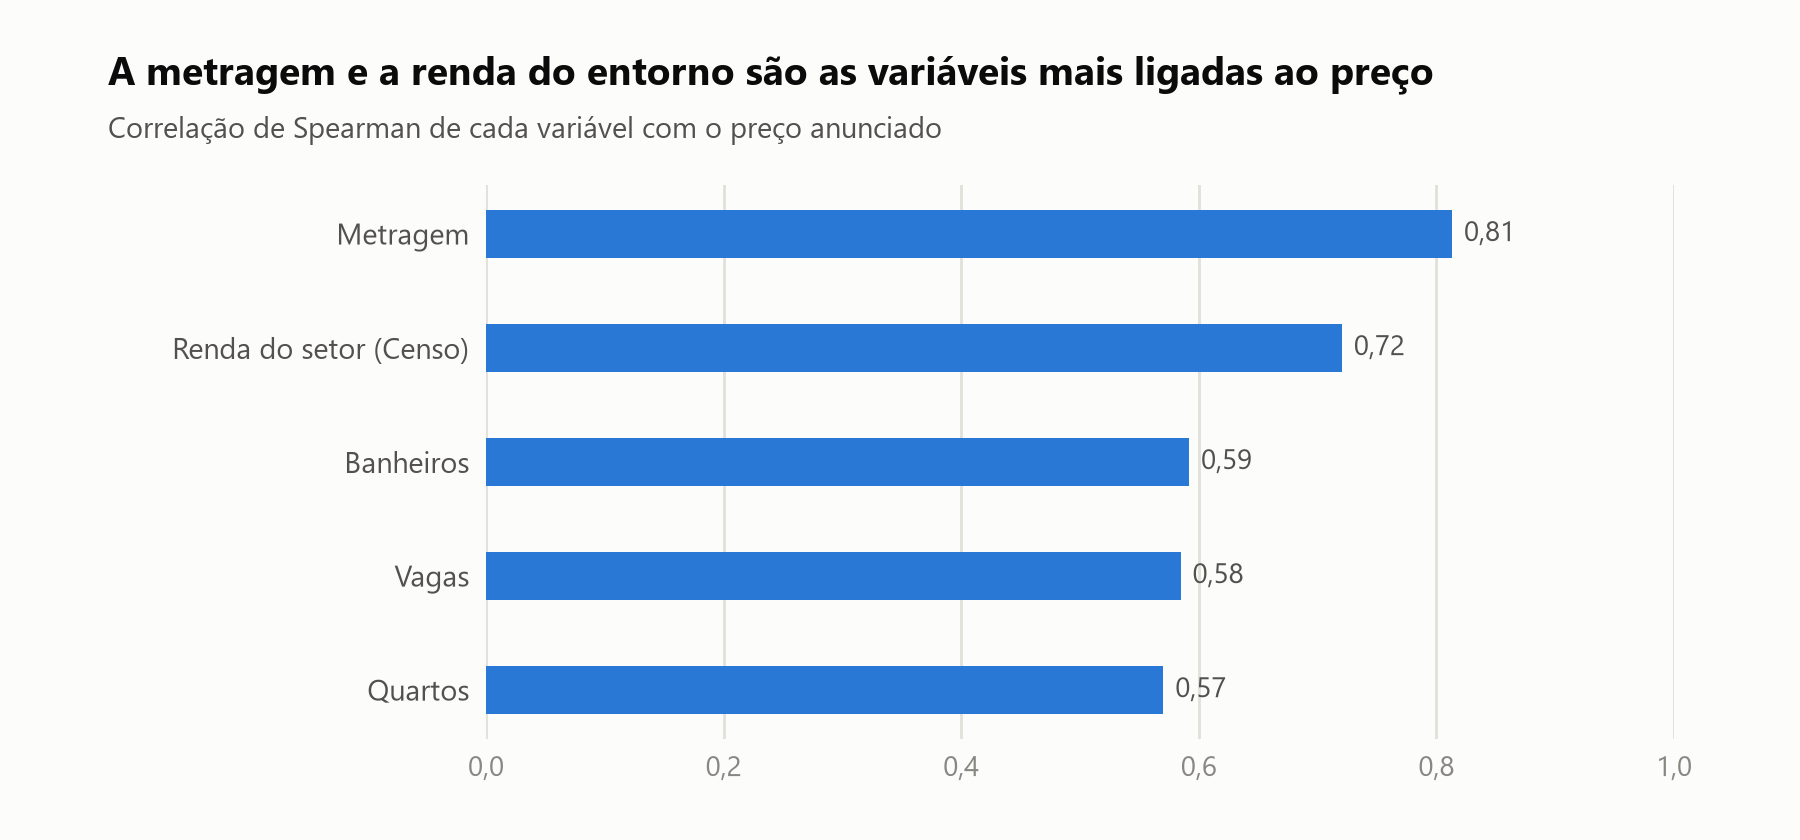

In [9]:
print(f"preço médio {milhoes(dados['Valor_anuncio'].mean())} x mediano {milhoes(dados['Valor_anuncio'].median())}")
nomes_curtos = {"Metragem": "Metragem", "Quartos": "Quartos", "Banheiros": "Banheiros", "Vagas": "Vagas",
                "renda_setor": "Renda do setor (Censo)"}
correlacao = dados[list(nomes_curtos)].corrwith(dados["Valor_anuncio"], method="spearman") \
    .rename(nomes_curtos).sort_values()


def desenhar_correlacao(fig, c):
    ax = fig.add_axes([0.27, 0.12, 0.66, 0.66])
    preparar_eixos(ax, c, grade="x")
    ax.barh(correlacao.index, correlacao.values, height=0.42, color=c["destaque"])
    for nome, valor in correlacao.items():
        ax.text(valor + 0.01, nome, decimal(valor), va="center", ha="left", fontsize=10, color=c["texto_sec"])
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: decimal(v, 1)))
    ax.tick_params(axis="y", colors=c["texto_sec"], labelsize=10.5)
    ax.spines["bottom"].set_visible(False)
    titulos(fig, c, "A metragem e a renda do entorno são as variáveis mais ligadas ao preço",
            "Correlação de Spearman de cada variável com o preço anunciado")


salvar_grafico(desenhar_correlacao, "correlacao_preco", tamanho=(9, 4.2))

## 4. Onde o metro quadrado é mais caro

Os anúncios ficam em 1.675 setores censitários diferentes, com uma mediana de 2 anúncios por setor: pouco para um mapa por setor. Por isso agrupo os setores por **distrito** (96 em São Paulo) e calculo a mediana do preço por m² em cada um. Distritos com menos de 10 anúncios ficam em cinza, porque uma mediana com tão poucos imóveis não é confiável.

In [10]:
MINIMO_ANUNCIOS = 10

# Só os setores da cidade de São Paulo (o arquivo tem o estado inteiro), unidos por distrito
setores = gpd.read_file(ARQUIVO_SETORES, where="CD_GEOCODM = '3550308'")
distritos = setores.dissolve(by=["CD_GEOCODD", "NM_DISTRIT"]).reset_index()[["CD_GEOCODD", "NM_DISTRIT", "geometry"]]
distritos = distritos.to_crs(31983)       # SIRGAS 2000 / UTM 23S: projeção em metros, sem distorcer a forma da cidade
distritos["geometry"] = distritos.buffer(5).buffer(-5)   # fecha as frestas de poucos metros que sobram entre setores vizinhos


def nome_bonito(nome):
    """'JARDIM DE ABRIL' -> 'Jardim de Abril'"""
    palavras = nome.title().split()
    return " ".join(p.lower() if p.lower() in {"de", "da", "do", "das", "dos", "e"} else p for p in palavras)


distritos["distrito"] = distritos["NM_DISTRIT"].map(nome_bonito)
por_distrito = dados.groupby("Cod_distrito").agg(anuncios=("Valor_m2", "size"), preco_m2=("Valor_m2", "median"))
mapa = distritos.merge(por_distrito, left_on="CD_GEOCODD", right_index=True, how="left")
mapa["anuncios"] = mapa["anuncios"].fillna(0).astype(int)

confiaveis = mapa["anuncios"] >= MINIMO_ANUNCIOS
classes, limites = pd.qcut(mapa.loc[confiaveis, "preco_m2"], 5, labels=False, retbins=True)    # 5 faixas com o mesmo número de distritos
mapa.loc[confiaveis, "classe"] = classes
print(f"{len(mapa)} distritos; {mapa['anuncios'].gt(0).sum()} com anúncios; {confiaveis.sum()} com {MINIMO_ANUNCIOS} ou mais")
dez_maiores = mapa.nlargest(10, "anuncios")
print(f"os 10 distritos com mais anúncios concentram {porcento(dez_maiores['anuncios'].sum() / len(dados), 0)} da base: "
      + ", ".join(dez_maiores["distrito"]))

96 distritos; 92 com anúncios; 56 com 10 ou mais
os 10 distritos com mais anúncios concentram 51% da base: Morumbi, Alto de Pinheiros, Saúde, Pinheiros, Perdizes, Vila Mariana, Campo Belo, Itaim Bibi, Moema, Santo Amaro


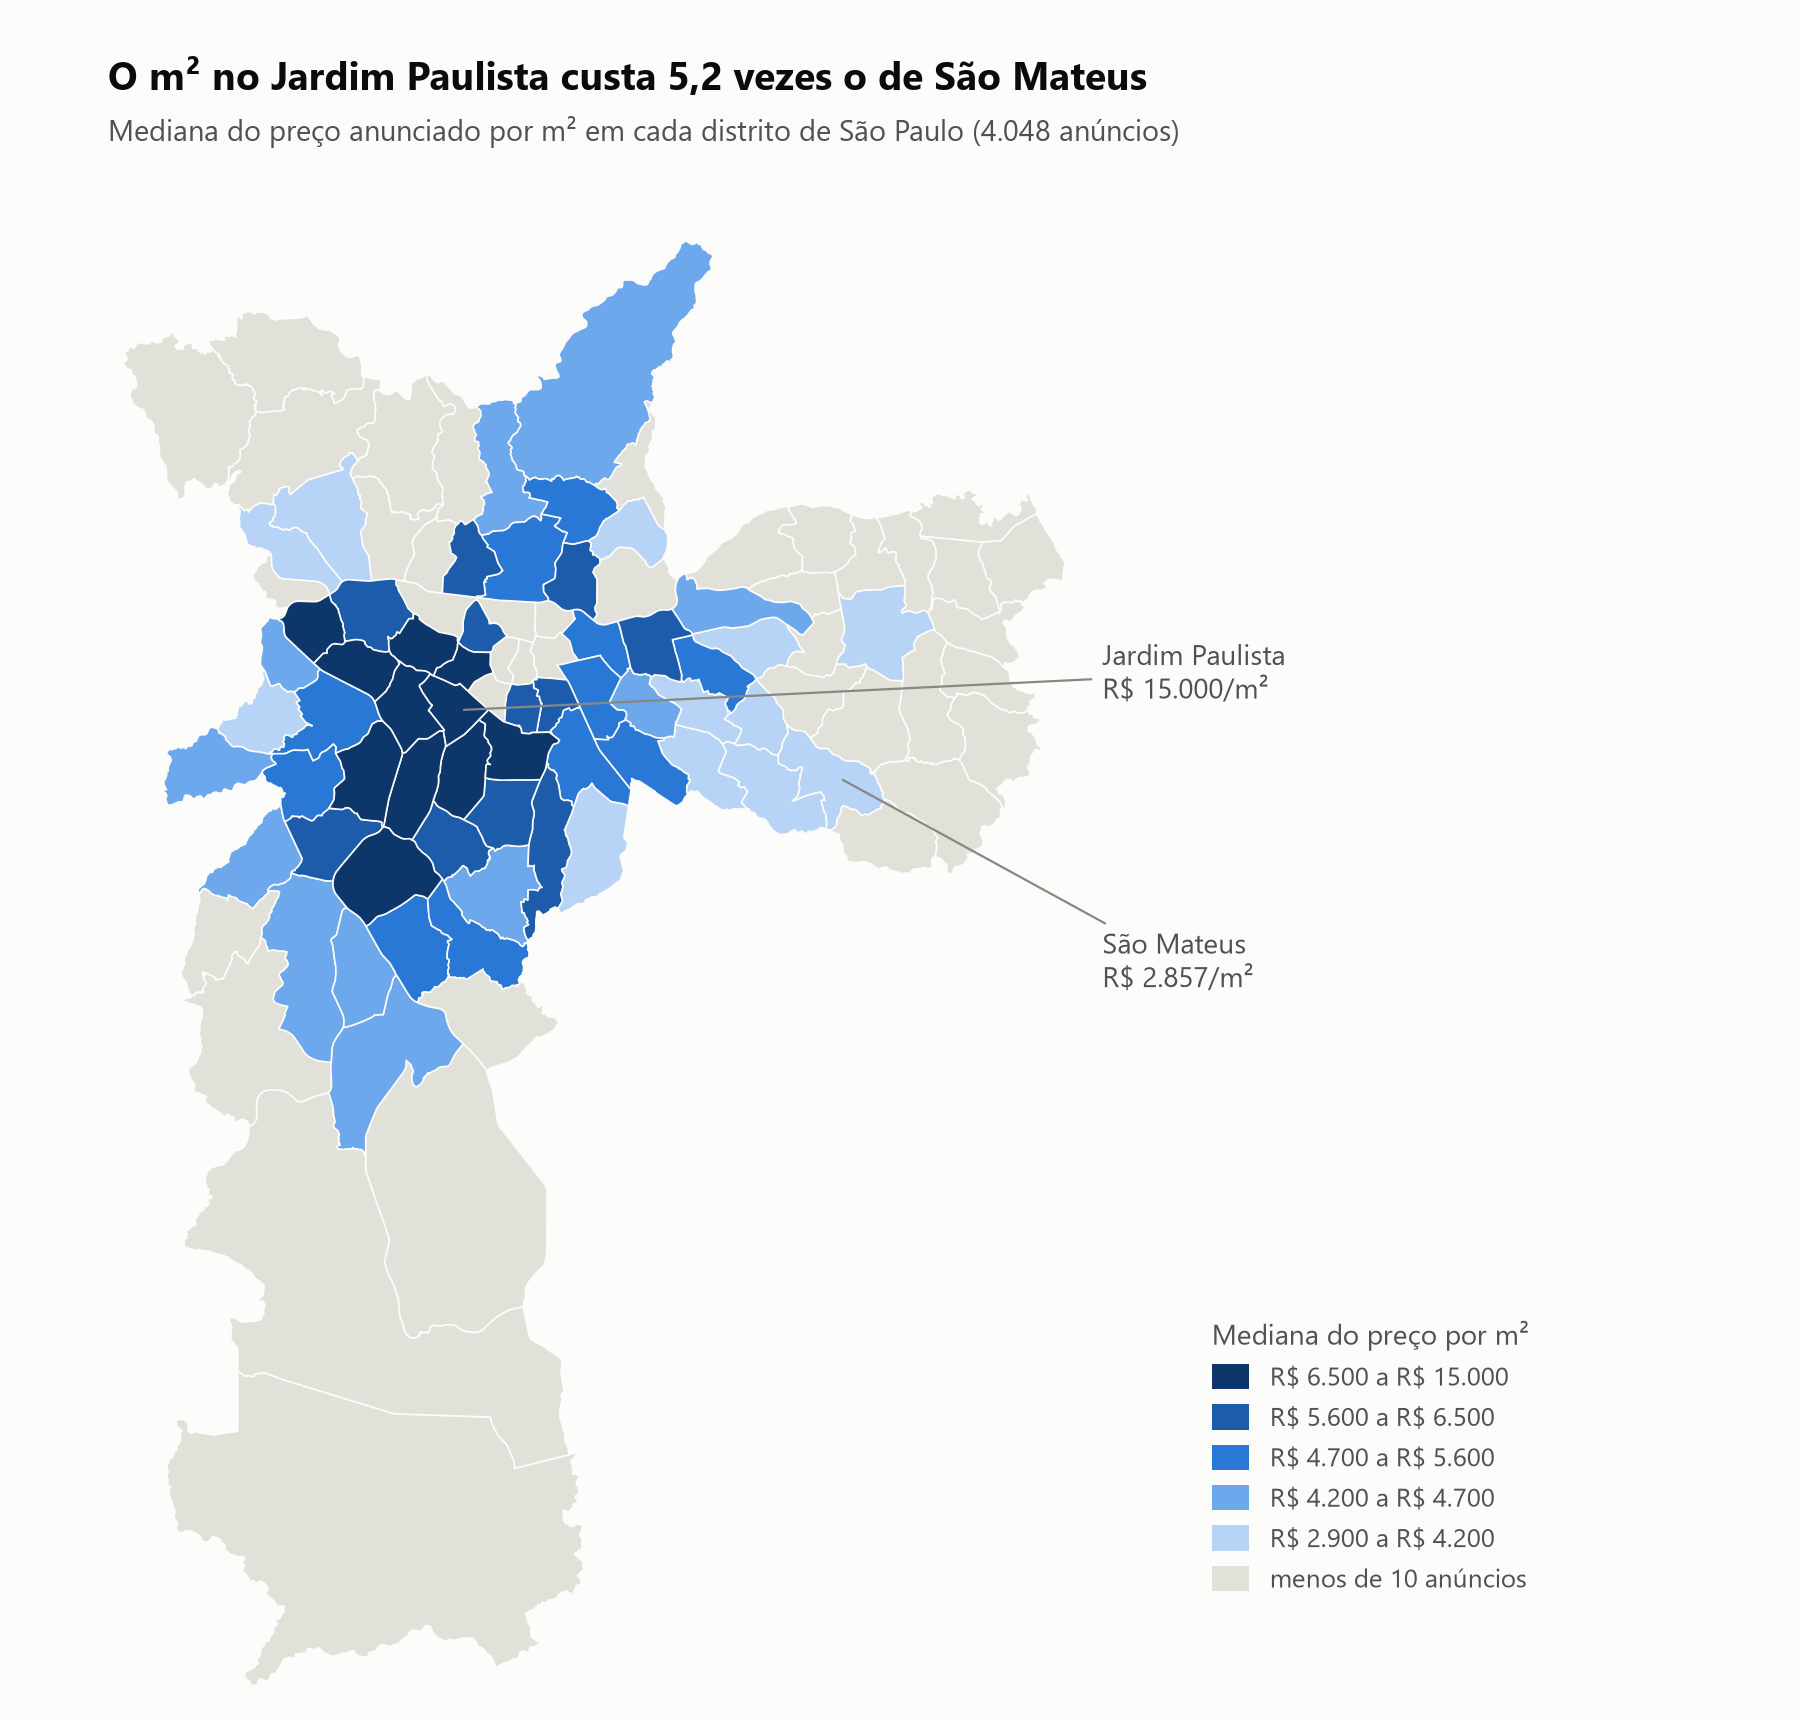

In [11]:
mais_caro = mapa[confiaveis].nlargest(1, "preco_m2").iloc[0]
mais_barato = mapa[confiaveis].nsmallest(1, "preco_m2").iloc[0]
faixas = [f"{reais(round(a, -2))} a {reais(round(b, -2))}" for a, b in zip(limites[:-1], limites[1:])]


def desenhar_mapa(fig, c):
    ax = fig.add_axes([0.02, 0.02, 0.62, 0.84])
    ax.set_axis_off()
    ax.margins(0)
    mapa[~confiaveis].plot(ax=ax, color=c["sem_dados"], edgecolor=c["superficie"], linewidth=0.6)
    for classe, cor in enumerate(c["escala"]):
        mapa[mapa["classe"] == classe].plot(ax=ax, color=cor, edgecolor=c["superficie"], linewidth=0.6)

    # Rótulos diretos só nos dois extremos, com linha-guia até a margem direita
    for distrito, y_texto in [(mais_caro, 0.70), (mais_barato, 0.50)]:
        ponto = distrito.geometry.representative_point()
        ax.annotate(f"{distrito['distrito']}\n{reais(distrito['preco_m2'])}/m²", xy=(ponto.x, ponto.y),
                    xytext=(1.04, y_texto), textcoords="axes fraction", ha="left", va="center", fontsize=10,
                    color=c["texto_sec"], arrowprops=dict(arrowstyle="-", color=c["texto_mudo"], linewidth=0.8))

    legenda = [Patch(facecolor=cor, label=faixa) for cor, faixa in zip(c["escala"][::-1], faixas[::-1])]
    legenda.append(Patch(facecolor=c["sem_dados"], label=f"menos de {MINIMO_ANUNCIOS} anúncios"))
    fig.legend(handles=legenda, loc="lower left", bbox_to_anchor=(0.66, 0.06), frameon=False, fontsize=9.5,
               labelcolor=c["texto_sec"], title="Mediana do preço por m²", title_fontsize=10, alignment="left",
               handlelength=1.4, handleheight=1.1)
    fig.legends[0].get_title().set_color(c["texto_sec"])
    razao = mais_caro["preco_m2"] / mais_barato["preco_m2"]
    titulos(fig, c, f"O m² no {mais_caro['distrito']} custa {decimal(razao, 1)} vezes o de {mais_barato['distrito']}",
            f"Mediana do preço anunciado por m² em cada distrito de São Paulo ({inteiro(len(dados))} anúncios)")


salvar_grafico(desenhar_mapa, "mapa_preco_m2_distrito", tamanho=(9, 8.6))

In [12]:
tabela_distritos = mapa[confiaveis].sort_values("preco_m2", ascending=False)[["distrito", "anuncios", "preco_m2"]] \
    .rename(columns={"distrito": "Distrito", "anuncios": "Anúncios", "preco_m2": "Mediana R$/m²"})
pd.concat([tabela_distritos.head(5), tabela_distritos.tail(5)])

,Distrito,Anúncios,Mediana R$/m²
44,Jardim Paulista,109,"15.000,00"
61,Pinheiros,198,"12.875,54"
31,Moema,149,"12.142,86"
34,Itaim Bibi,161,"10.204,08"
25,Consolação,60,"9.452,38"
71,São Lucas,23,"3.642,86"
91,Vila Medeiros,14,"3.473,49"
75,Sapopemba,12,"3.354,17"
36,Itaquera,11,"3.134,33"
72,São Mateus,21,"2.857,14"


### 4.1 Um sinal de erro na geolocalização

O distrito de São Rafael, no extremo leste, ficou em cinza por ter poucos anúncios, mas os anúncios atribuídos a ele mostram um problema herdado da aula 04. Segundo a coluna `Bairro` do próprio anúncio, alguns são da Mooca e do Jardim Petrópolis, a dezenas de quilômetros. A geolocalização usou só o nome da rua, e ruas com o mesmo nome existem em vários pontos da cidade.

In [13]:
codigo_sao_rafael = mapa.loc[mapa["distrito"] == "São Rafael", "CD_GEOCODD"].iloc[0]
dados.loc[dados["Cod_distrito"] == codigo_sao_rafael, ["Rua", "Bairro", "Metragem", "Valor_anuncio", "Valor_m2"]]

,Rua,Bairro,Metragem,Valor_anuncio,Valor_m2
33,"Rua Professor Ciro Formicola, 203",Parque São Rafael,125,"425.000,00","3.400,00"
645,Rua Gonçalves Ferreira,Parque São Rafael,120,"380.000,00","3.166,67"
3379,"Rua Franca do Imperador, 241",Jardim Vera Cruz(Zona Leste),640,"350.000,00","546,88"
3402,Rua São Rafael,Mooca,84,"750.000,00","8.928,57"
3855,Rua Péricles,Jardim Petrópolis,900,"13.000.000,00","14.444,44"
4137,Largo São Rafael,Mooca,103,"750.000,00","7.281,55"
4712,Rua Cachoeira Branca,Parque São Rafael,250,"386.250,00","1.545,00"


## 5. O modelo do curso e o sítio de 37.000 m²

Na aula 05, a regressão linear do preço pela metragem teve R² de 0,13 no conjunto de teste. Refazendo exatamente a mesma divisão de treino e teste, mas sem o sítio de 37.000 m², o resultado muda bastante: o sítio, com área enorme e preço baixo, "achatava" a reta.

In [14]:
def modelo_do_curso(base):
    """Mesma divisão e modelo da aula 05: preço ~ metragem, 25% para teste, semente 54."""
    X_treino, X_teste, y_treino, y_teste = train_test_split(base[["Metragem"]], base["Valor_anuncio"],
                                                            test_size=0.25, random_state=SEMENTE)
    modelo = LinearRegression().fit(X_treino, y_treino)
    return modelo, r2_score(y_teste, modelo.predict(X_teste))


reta_curso, r2_curso = modelo_do_curso(curso)
reta_sem_sitio, r2_sem_sitio = modelo_do_curso(sem_sitio)
print(f"com o sítio: R² = {decimal(r2_curso)}; preço = {reais(reta_curso.intercept_)} + {reais(reta_curso.coef_[0])} por m²")
print(f"sem o sítio: R² = {decimal(r2_sem_sitio)}; preço = {reais(reta_sem_sitio.intercept_)} + {reais(reta_sem_sitio.coef_[0])} por m²")

com o sítio: R² = 0,13; preço = R$ 2.235.552 + R$ 1.400 por m²
sem o sítio: R² = 0,42; preço = R$ -514.398 + R$ 9.779 por m²


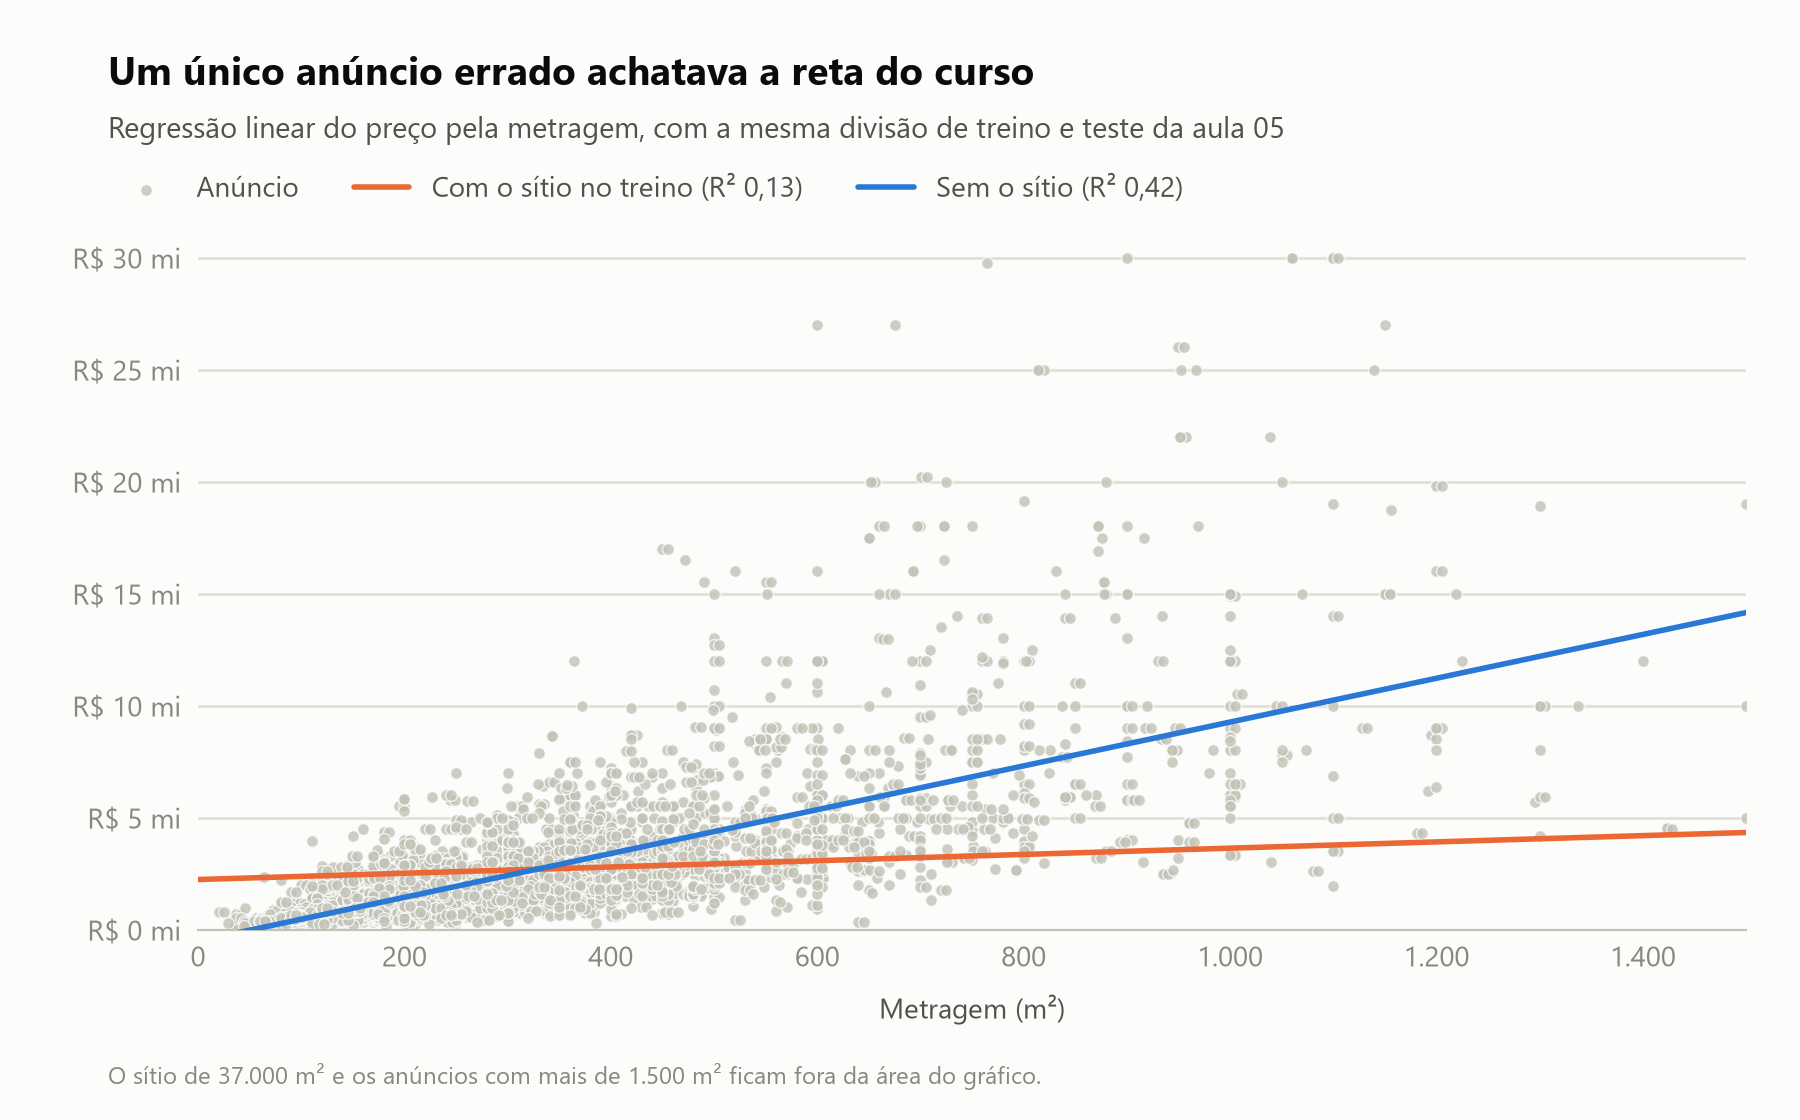

In [15]:
LIMITE_METRAGEM = 1500
visiveis = sem_sitio[sem_sitio["Metragem"] <= LIMITE_METRAGEM]
x_reta = np.array([0, LIMITE_METRAGEM])


def desenhar_regressao(fig, c):
    ax = fig.add_axes([0.11, 0.17, 0.86, 0.62])
    preparar_eixos(ax, c)
    ax.scatter(visiveis["Metragem"], visiveis["Valor_anuncio"] / 1e6, s=18, color=c["apagado"], alpha=0.8,
               edgecolors=c["superficie"], linewidths=0.5, label="Anúncio", zorder=2)
    for reta, cor, rotulo in [(reta_curso, c["contraste"], f"Com o sítio no treino (R² {decimal(r2_curso)})"),
                              (reta_sem_sitio, c["destaque"], f"Sem o sítio (R² {decimal(r2_sem_sitio)})")]:
        y_reta = reta.predict(pd.DataFrame({"Metragem": x_reta})) / 1e6
        ax.plot(x_reta, y_reta, color=cor, linewidth=2, solid_capstyle="round", label=rotulo, zorder=3)
    ax.set_xlim(0, LIMITE_METRAGEM)
    ax.set_ylim(0, 31)
    ax.set_yticks(range(0, 31, 5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: inteiro(v)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"R$ {v:.0f} mi"))
    ax.set_xlabel("Metragem (m²)", color=c["texto_sec"], fontsize=10, labelpad=8)
    fig.legend(loc="upper left", bbox_to_anchor=(0.052, 0.868), ncol=3, frameon=False, fontsize=10,
               labelcolor=c["texto_sec"], columnspacing=2)
    titulos(fig, c, "Um único anúncio errado achatava a reta do curso",
            "Regressão linear do preço pela metragem, com a mesma divisão de treino e teste da aula 05",
            f"O sítio de 37.000 m² e os anúncios com mais de {inteiro(LIMITE_METRAGEM)} m² ficam fora da área do gráfico.")


salvar_grafico(desenhar_regressao, "regressao_metragem")

## 6. Comparação de modelos

Agora com a base limpa (sem o sítio e sem duplicatas), comparo cinco modelos com **validação cruzada em 5 partes**: cada anúncio é usado 4 vezes no treino e 1 vez no teste, e as métricas são a média das 5 rodadas. Todos os modelos usam as mesmas partes.

| Modelo | Variáveis |
|---|---|
| Referência | nenhuma: prevê sempre o preço médio do treino |
| Curso | metragem |
| Regressão com 5 variáveis | metragem, quartos, banheiros, vagas e renda do setor |
| Regressão em log | as mesmas 5, com log no preço, na metragem e na renda |
| Árvores + localização | as mesmas 5, mais latitude e longitude, com log no preço (`HistGradientBoostingRegressor`) |

Uso três métricas, todas calculadas em reais (os modelos em log têm a previsão convertida de volta):

- **Erro percentual mediano**: em metade dos imóveis, o erro é menor do que este percentual do preço. É a mais fácil de interpretar e não é dominada pelos imóveis de dezenas de milhões.
- **Erro médio absoluto**: quanto o modelo erra em média, em reais.
- **R²**: quanto da variação do preço o modelo explica (1 = tudo, 0 = o mesmo que prever a média).

In [16]:
def erro_pct_mediano(y, previsto):
    y, previsto = np.asarray(y), np.asarray(previsto)
    return np.median(np.abs(previsto - y) / y)


def em_log(modelo):
    """Treina no log do preço e devolve a previsão em reais."""
    return TransformedTargetRegressor(regressor=modelo, func=np.log, inverse_func=np.exp)


casa = ["Metragem", "Quartos", "Banheiros", "Vagas", "renda_setor"]
log_metragem_renda = ColumnTransformer([("log", FunctionTransformer(np.log), ["Metragem", "renda_setor"])],
                                       remainder="passthrough")
modelos = {
    "Referência: sempre a média": (DummyRegressor(), ["Metragem"]),
    "Curso: só a metragem": (LinearRegression(), ["Metragem"]),
    "Regressão com 5 variáveis": (LinearRegression(), casa),
    "Regressão em log": (em_log(make_pipeline(log_metragem_renda, LinearRegression())), casa),
    "Árvores + localização": (em_log(HistGradientBoostingRegressor(random_state=SEMENTE)), casa + ["latitude", "longitude"]),
}
metricas = {"mdape": make_scorer(erro_pct_mediano, greater_is_better=False),
            "mae": "neg_mean_absolute_error", "r2": "r2"}
partes = KFold(n_splits=5, shuffle=True, random_state=SEMENTE)

resultados = {}
for nome, (modelo, X_cols) in modelos.items():
    r = cross_validate(modelo, dados[X_cols], dados["Valor_anuncio"], cv=partes, scoring=metricas)
    resultados[nome] = {"mdape": -r["test_mdape"], "mae": -r["test_mae"], "r2": r["test_r2"]}

tabela = pd.DataFrame({
    nome: {"Erro percentual mediano": f"{porcento(m['mdape'].mean())} ± {decimal(100 * m['mdape'].std(), 1)}",
           "Erro médio absoluto": f"{milhoes(m['mae'].mean())} ± {decimal(m['mae'].std() / 1e6)}",
           "R²": f"{decimal(m['r2'].mean())} ± {decimal(m['r2'].std())}"}
    for nome, m in resultados.items()}).T
tabela

,Erro percentual mediano,Erro médio absoluto,R²
Referência: sempre a média,"76,9% ± 3,3","R$ 1,98 mi ± 0,08","0,00 ± 0,00"
Curso: só a metragem,"37,6% ± 1,8","R$ 1,20 mi ± 0,08","0,50 ± 0,05"
Regressão com 5 variáveis,"37,0% ± 1,5","R$ 1,18 mi ± 0,07","0,51 ± 0,05"
Regressão em log,"27,7% ± 1,0","R$ 1,08 mi ± 0,07","0,46 ± 0,05"
Árvores + localização,"20,4% ± 1,0","R$ 0,76 mi ± 0,06","0,73 ± 0,03"


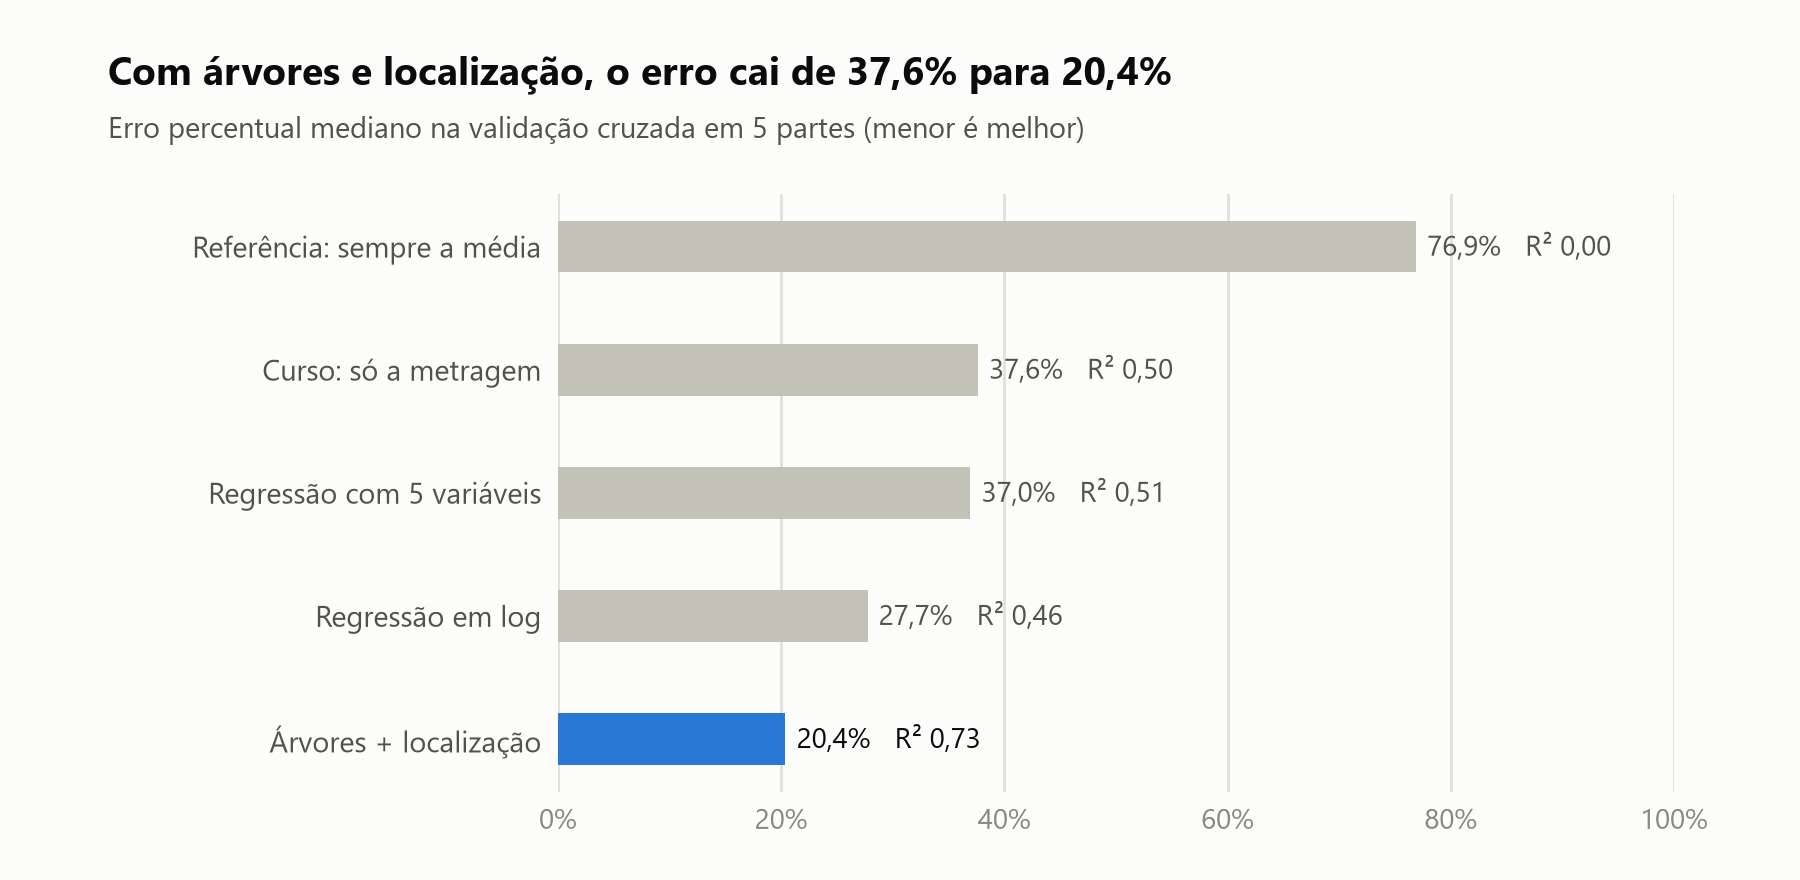

In [17]:
resumo = pd.DataFrame({nome: {"mdape": m["mdape"].mean(), "r2": m["r2"].mean()} for nome, m in resultados.items()}).T
melhor = resumo["mdape"].idxmin()


def desenhar_comparacao(fig, c):
    ax = fig.add_axes([0.31, 0.1, 0.62, 0.68])
    preparar_eixos(ax, c, grade="x")
    nomes = resumo.index[::-1]             # o primeiro modelo fica no topo
    cores = [c["destaque"] if nome == melhor else c["apagado"] for nome in nomes]
    ax.barh(nomes, resumo.loc[nomes, "mdape"] * 100, height=0.42, color=cores)
    for nome in nomes:
        valor = resumo.loc[nome, "mdape"] * 100
        ax.text(valor + 1, nome, f"{decimal(valor, 1)}%   R² {decimal(resumo.loc[nome, 'r2'])}",
                va="center", ha="left", fontsize=10,
                color=c["texto"] if nome == melhor else c["texto_sec"])
    ax.set_xlim(0, 100)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.tick_params(axis="y", colors=c["texto_sec"], labelsize=10.5)
    ax.spines["bottom"].set_visible(False)
    erro_curso = resumo.loc["Curso: só a metragem", "mdape"]
    titulos(fig, c, f"Com árvores e localização, o erro cai de {porcento(erro_curso)} para {porcento(resumo.loc[melhor, 'mdape'])}",
            "Erro percentual mediano na validação cruzada em 5 partes (menor é melhor)")


salvar_grafico(desenhar_comparacao, "comparacao_modelos", tamanho=(9, 4.4))

### 6.1 Quanto as duplicatas enganariam a avaliação

Para medir o efeito das duplicatas, repito a validação cruzada do melhor modelo na base **com** as duplicatas. A diferença é o quanto o resultado pareceria melhor do que realmente é.

In [18]:
modelo, X_cols = modelos["Árvores + localização"]
r = cross_validate(modelo, sem_sitio[X_cols], sem_sitio["Valor_anuncio"], cv=partes, scoring=metricas)
pd.DataFrame({
    "Erro percentual mediano": [porcento(resultados["Árvores + localização"]["mdape"].mean()), porcento(-r["test_mdape"].mean())],
    "R²": [decimal(resultados["Árvores + localização"]["r2"].mean()), decimal(r["test_r2"].mean())],
}, index=["Sem duplicatas (avaliação correta)", "Com duplicatas (otimista)"])

,Erro percentual mediano,R²
Sem duplicatas (avaliação correta),"20,4%","0,73"
Com duplicatas (otimista),"18,4%","0,79"


## 7. O que mais pesa no preço

Para saber quanto o melhor modelo depende de cada variável, uso **importância por permutação**: treino o modelo com 75% dos anúncios e, nos 25% restantes, embaralho uma variável de cada vez e meço quanto o erro piora. Latitude e longitude são embaralhadas juntas, como uma variável só (a localização).

In [19]:
modelo, X_cols = modelos["Árvores + localização"]
X_treino, X_teste, y_treino, y_teste = train_test_split(dados[X_cols], dados["Valor_anuncio"],
                                                        test_size=0.25, random_state=SEMENTE)
modelo.fit(X_treino, y_treino)
erro_base = erro_pct_mediano(y_teste, modelo.predict(X_teste))

grupos = {"Localização": ["latitude", "longitude"], "Metragem": ["Metragem"], "Banheiros": ["Banheiros"],
          "Vagas": ["Vagas"], "Quartos": ["Quartos"], "Renda do setor (Censo)": ["renda_setor"]}
sorteio = np.random.default_rng(SEMENTE)
importancia = {}
for nome, cols in grupos.items():
    aumentos = []
    for _ in range(20):
        embaralhado = X_teste.copy()
        embaralhado[cols] = X_teste[cols].to_numpy()[sorteio.permutation(len(X_teste))]
        aumentos.append(erro_pct_mediano(y_teste, modelo.predict(embaralhado)) - erro_base)
    importancia[nome] = np.mean(aumentos)
importancia = pd.Series(importancia).sort_values()
print(f"erro percentual mediano no teste: {porcento(erro_base)}")
(importancia * 100).round(1).rename("aumento do erro (pontos percentuais)").to_frame().iloc[::-1]

erro percentual mediano no teste: 22,0%


,aumento do erro (pontos percentuais)
Metragem,"21,70"
Localização,"14,70"
Renda do setor (Censo),"7,50"
Vagas,"1,80"
Banheiros,"1,50"
Quartos,"0,50"


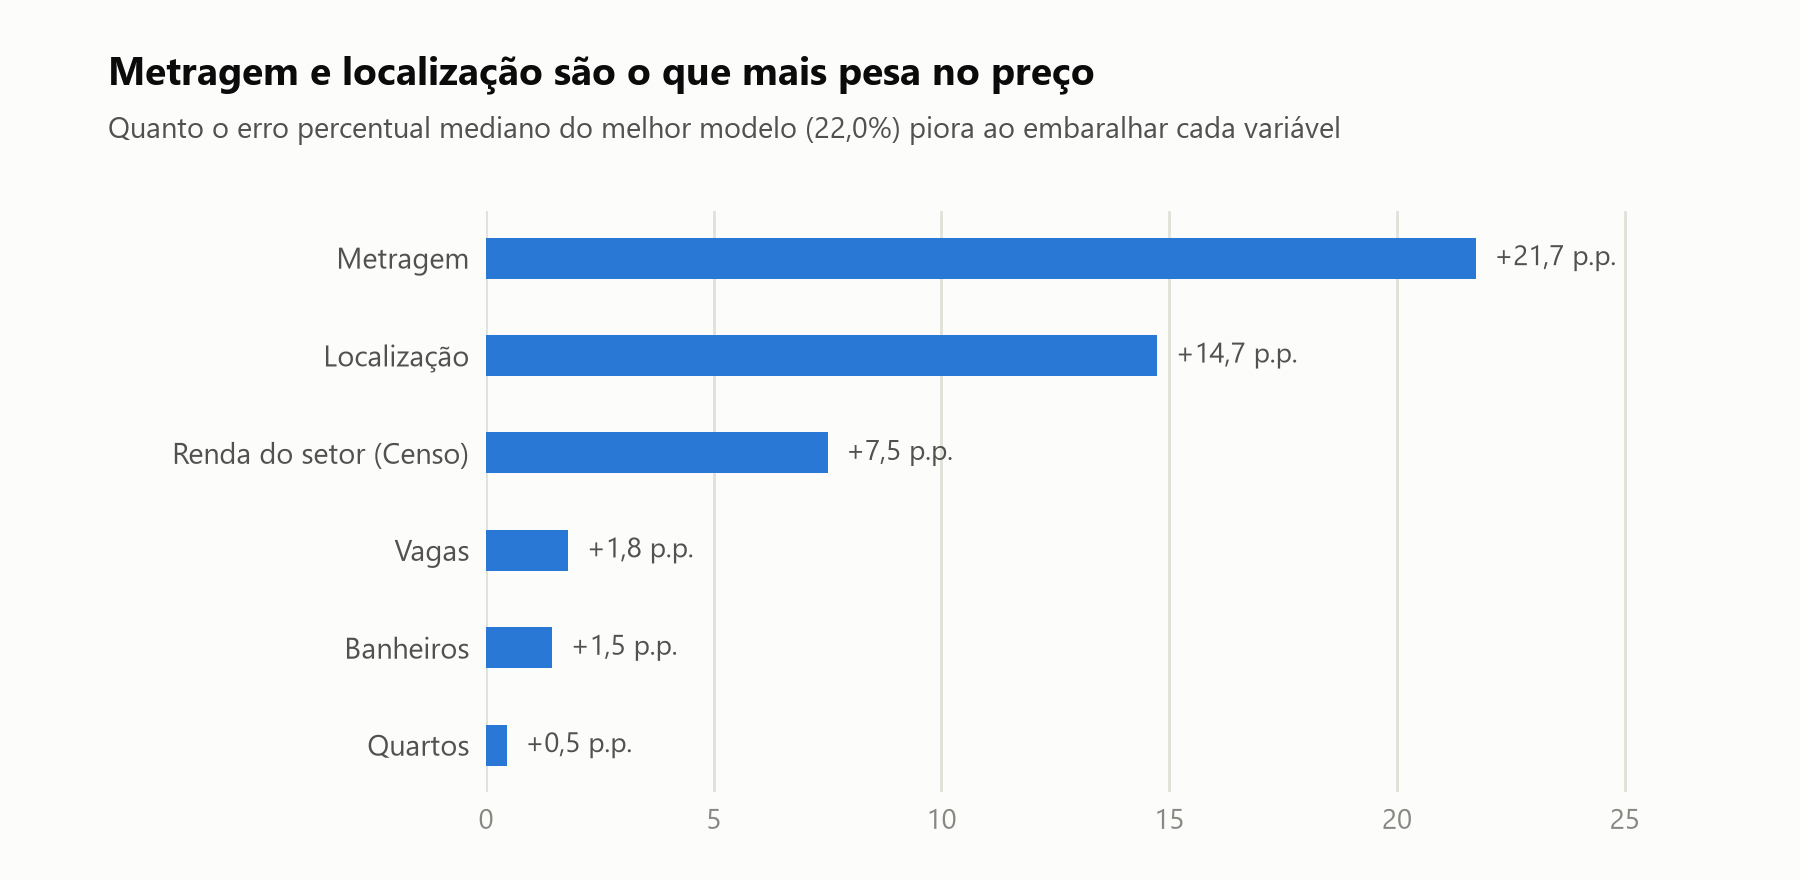

In [20]:
def desenhar_importancia(fig, c):
    ax = fig.add_axes([0.27, 0.1, 0.66, 0.66])
    preparar_eixos(ax, c, grade="x")
    ax.barh(importancia.index, importancia.values * 100, height=0.42, color=c["destaque"])
    for nome, valor in importancia.items():
        ax.text(valor * 100 + 0.4, nome, f"+{decimal(valor * 100, 1)} p.p.", va="center", ha="left",
                fontsize=10, color=c["texto_sec"])
    ax.set_xlim(0, importancia.max() * 100 * 1.2)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
    ax.tick_params(axis="y", colors=c["texto_sec"], labelsize=10.5)
    ax.spines["bottom"].set_visible(False)
    titulos(fig, c, f"{importancia.index[-1]} e {importancia.index[-2].lower()} são o que mais pesa no preço",
            f"Quanto o erro percentual mediano do melhor modelo ({porcento(erro_base)}) piora ao embaralhar cada variável")


salvar_grafico(desenhar_importancia, "importancia_variaveis", tamanho=(9, 4.4))

## 8. Conclusões

1. **Limpar os dados rendeu mais do que trocar de modelo.** Com o mesmo modelo do curso, tirar um único anúncio errado levou o R² de 0,13 para 0,42. Sem tirar as duplicatas, o melhor modelo pareceria melhor do que é: erro de 18,4% em vez de 20,4%.
2. **A localização é a segunda variável mais importante, logo depois da metragem.** Ela entra no modelo de árvores como latitude e longitude. A regressão linear não conseguiria aproveitá-las, porque o preço não sobe de forma regular em nenhuma direção.
3. **O cruzamento com o Censo valeu a pena.** A renda dos responsáveis pelos domicílios do setor é a terceira variável mais importante, mesmo sendo de 2010.
4. **Ainda sobra um erro de cerca de 20%.** Os anúncios não dizem o estado de conservação, a idade do imóvel, o padrão de acabamento nem se a metragem é de área construída ou de terreno. Provavelmente é aí que está boa parte do que falta explicar.

### Limitações

- **Preço de anúncio, não de venda.** O valor negociado costuma ser menor, e a diferença pode variar por região.
- **Censo de 2010.** As variáveis do IBGE descrevem os setores mais de uma década antes dos anúncios.
- **Geolocalização pelo nome da rua.** Na aula 04, cada anúncio recebeu as coordenadas de uma rua com o mesmo nome. Ruas homônimas jogaram alguns anúncios no distrito errado (seção 4.1), o que adiciona ruído ao mapa e à variável de localização.
- **Amostra concentrada.** Os 10 distritos com mais anúncios, todos nas zonas sul e oeste, concentram 51% da base. Boa parte das zonas leste e norte e do extremo sul tem menos de 10 anúncios por distrito.

### Próximos passos

- Validar a geolocalização com o CEP ou o número do imóvel, e não só o nome da rua.
- Usar dados do Censo 2022, quando os agregados por setor estiverem disponíveis.
- Ajustar os hiperparâmetros do modelo de árvores e estimar intervalos de previsão, além do valor pontual.